# From 1D GRE to fully-relaxed 2D GRE sequence
Now, let's move from spectroscopy to imaging using 2D spatial encoding!:)   
**Exercise**
1. This is a simple 1D GRE sequence with readout in x direction. Could you add a gradient in y direction for **phase encoding**?
2. Do you know why there are artifacts in the reconstructed image? How can you suppress these artifacts? (Hint: try to change TR for **full relaxation**)
3. (optional) instead of increasing TR, you can also use **RF/gradient spoilers** to dephase residual magnetization. A "**gradient surgery**" can be used to even shorten TR. Uncomment the gradient spoiling part and get familiar with it. The concept of spoiling will be introduced in the topic: "Gradient echoes and steady state" later. The gradient surgery will also be used in later lectures, such as EPI and MRS.


In [39]:
#@title 2D GRE in a  brain phantom - environment setup
!pip show pypulseq || pip install pypulseq &> /dev/null
import math
import warnings
import numpy as np
from matplotlib import pyplot as plt
import pypulseq as pp
# for simulation
!pip show MRzeroCore || pip install MRzeroCore
import MRzeroCore as mr0

Name: pypulseq
Version: 1.5.0.post1
Summary: Pulseq in Python
Home-page: https://github.com/imr-framework/pypulseq
Author: 
Author-email: Keerthi Sravan Ravi <ks3621@columbia.edu>
License: MIT License

Copyright (c) 2019-2025 PyPulseq Contributors

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONI

Timing check passed successfully


/tmp/ipykernel_374410/744459546.py:26: UserWarning: Specified RF delay 0.00 us is less than the dead time 100 us. Delay was increased to the dead time.
  rf_ex = pp.make_block_pulse(flip_angle=alpha*np.pi/180, duration=1e-3, phase_offset=0*np.pi/180, system=system)
/tmp/ipykernel_374410/744459546.py:29: UserWarning: Specified ADC delay 0.00 us is less than the dead time 20 us. Delay was increased to the dead time.
  adc = pp.make_adc(num_samples=Nread, duration=5.12e-3, phase_offset=0*np.pi/180, system=system)


'e409ec68d0c5e85dd462f94fd1e31470'

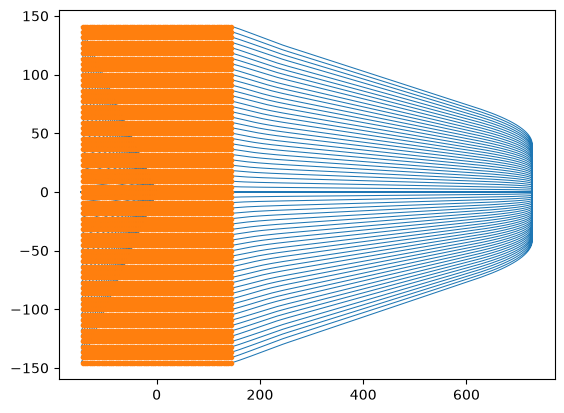

In [ ]:
#@title 2D GRE in a brain phantom - sequence
# %% DEFINE the sequence, FOV and resolution
fov=220e-3
Nread=64
Nphase=Nread
Nrep=1
TE=6e-3
TR=20e-3 # hint: use short TR for increased T1 contrast
# hint: add flip angle alpha as a parameter and calculate an Ernst engle for the optimal signal; increase it a bit for better T1 contrast
alpha = 20  
# hint: add dummy scan number parameter
Ndummy = 30

experiment_id = 'gre2d_rf_spoil'
# %% SETUP system
# choose the scanner limits
system = pp.Opts(
    max_grad=28, grad_unit='mT/m', max_slew=150, slew_unit='T/m/s',
    rf_ringdown_time=20e-6, rf_dead_time=100e-6,
    adc_dead_time=20e-6, grad_raster_time=10e-6)

seq=pp.Sequence(system)

# Define rf event
# hard pulse for excitation
rf_ex = pp.make_block_pulse(flip_angle=alpha*np.pi/180, duration=1e-3, phase_offset=0*np.pi/180, system=system)

# Define ADC event and gradients
adc = pp.make_adc(num_samples=Nread, duration=5.12e-3, phase_offset=0*np.pi/180, system=system)
deltak = 1/fov
# readout gradient
gx = pp.make_trapezoid(channel='x', flat_area=Nread*deltak, rise_time=adc.delay,flat_time=adc.dwell*adc.num_samples, system=system)
gxPre = pp.make_trapezoid(channel='x', area=-gx.area/2, duration=1e-3, system=system)

# Do a "gradient surgery" for spoiling.
# we cut the RO gradient into two parts for the optimal spoiler timing
gx1, _ = pp.split_gradient_at(grad=gx, time_point=gx.rise_time+gx.flat_time)
# gradient spoiling
gxSpoil = pp.make_extended_trapezoid_area(channel=gx.channel, grad_start=gx.amplitude, grad_end=0, area=2*Nread*deltak, system=system)[0]
gxSpoil.delay = pp.calc_duration(gx1)
gx_add = pp.add_gradients(grads=(gx1, gxSpoil),system=system)

# calculate timing
delayTE = np.ceil((TE-pp.calc_duration(gxPre) - rf_ex.shape_dur/2-rf_ex.ringdown_time-adc.delay-adc.dwell*adc.num_samples/2)/seq.grad_raster_time)*seq.grad_raster_time
delayTR = np.ceil((TR - pp.calc_duration(rf_ex) - delayTE - pp.calc_duration(gxPre) - pp.calc_duration(gx))/seq.grad_raster_time)*seq.grad_raster_time ;
assert(delayTE>=0)
assert(delayTR>=0)
# ======
# CONSTRUCT SEQUENCE
# ======

rf_phase_deg = 0 # hint: initialize an RF phase counter for RF spoiling
rf_inc_deg = 0 # 

for i in range(-Ndummy, Nphase): # hint: start with a negative counter to indicate dummy runs and skip phase encoding and acquisition if i<0
  rf_inc_deg += 117 # hint: increment the RF phase increment by a chosen quadratic increment, e.g. 84, 50 or 117 degrees
  rf_inc_deg = rf_inc_deg % 360 # hint: wrap the RF phase increment to 0-360 degrees
  rf_phase_deg += rf_inc_deg
  rf_phase_deg = rf_phase_deg % 360 # hint: wrap the RF phase to 0-360 degrees
  rf_ex.phase_offset = rf_phase_deg*np.pi/180
  seq.add_block(rf_ex) # hint: modify the RF phase for each TR prior to calling seq.add_block(rf_ex)
  seq.add_block(pp.make_delay(delayTE))
  if i>=0: # hint: skip phase encoding and acquisition if i<0
    gyPre = pp.make_trapezoid(channel='y',area=(i-Nphase/2)*deltak, duration=pp.calc_duration(gxPre),system=system)
    gyReph = pp.scale_grad(gyPre, -1)
    gyReph.delay = pp.calc_duration(gx1)
    seq.add_block(gxPre, gyPre)
    adc.phase_offset = rf_phase_deg*np.pi/180
    seq.add_block(gx_add, adc, gyReph) # hint: remember to add RF phase to the ADC event as well
  else:
    seq.add_block(gxPre)
    seq.add_block(gx_add)
  seq.add_block(pp.make_delay(delayTR))

(ok, error_report) = seq.check_timing()  # Check whether the timing of the sequence is correct
if ok:
    print("Timing check passed successfully")
else:
    print("Timing check failed. Error listing follows:")
    [print(e) for e in error_report]

# Plot k-space trajectory
k_traj_adc, k_traj, t_excitation, t_refocusing, t_adc = seq.calculate_kspace()

plt.figure()
plt.plot(k_traj[0],k_traj[1])
plt.plot(k_traj_adc[0],k_traj_adc[1],'.')

# Prepare the sequence output for the scanner
seq.set_definition('Name', 'gre2d')
seq.write('04_gre1d2gre2d.seq')

VoxelGridPhantom
size = tensor([0.2000, 0.2000, 0.0080])


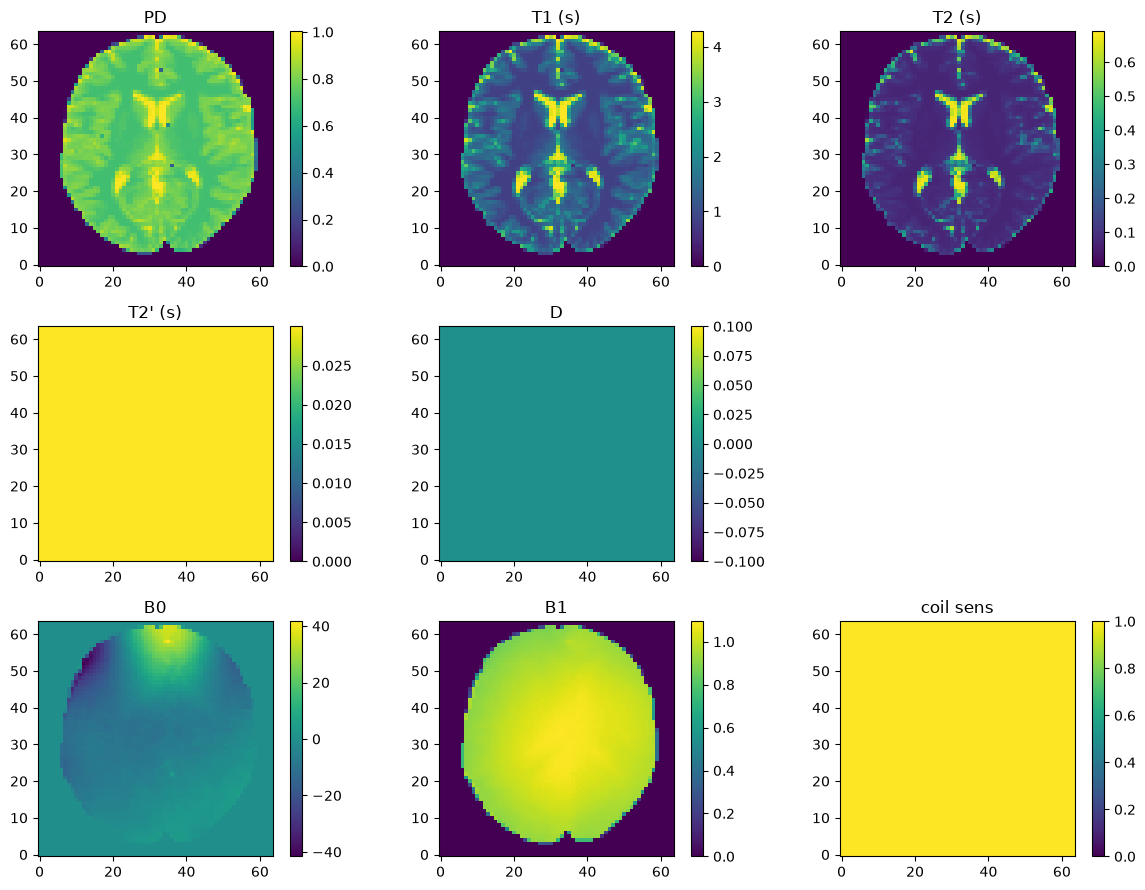

>>>> Rust - compute_graph(...) >>>
Converting Python -> Rust: 0.001014242 s
Compute Graph
Computing Graph: 0.018488487 s
Analyze Graph
Analyzing Graph: 0.000862476 s
Converting Rust -> Python: 0.008130988 s
<<<< Rust <<<<


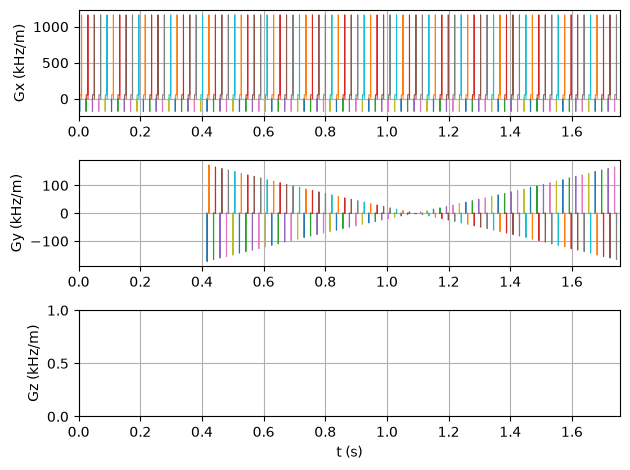

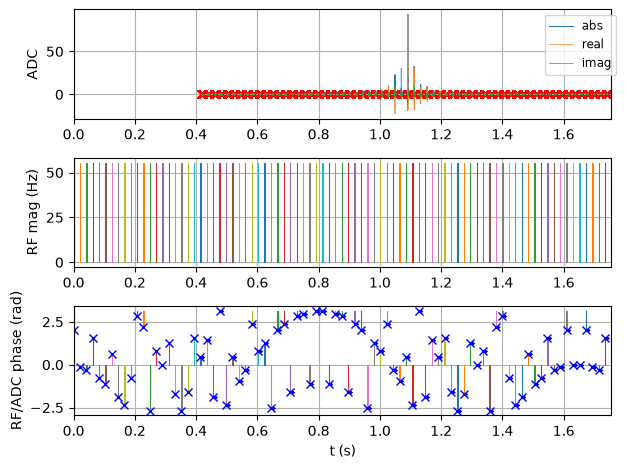

In [41]:
#@title 2D GRE in a brain phantom - simulation
dB0 = 0
sz = [64, 64]
# Load the MR0's default digital brain phantom (auto-downloads if missing)
obj_p = mr0.util.load_phantom(sz)  # the parameters are the maatrix size
# Manipulate loaded data
obj_p.T2dash[:] = 30e-3
#obj_p.D *= 0  # do not reset diffusion, as it is important for the physics of RF spoiling
obj_p.B0 *= 1    # alter the B0 inhomogeneity
# Store PD and B0 for comparison # hint: stote T1 as well
PD = obj_p.PD
B0 = obj_p.B0
T1 = obj_p.T1
# Manipulate loaded data
obj_p.B0+=dB0
obj_p.D*=0
obj_p.plot()
# Convert Phantom into simulation data
obj_p=obj_p.build()

# %% SIMULATE  the external.seq file and add acquired signal to ADC plot
# Read in the sequence
seq0 = mr0.Sequence.import_file("04_gre1d2gre2d.seq")
#seq0.plot_kspace_trajectory()
# Simulate the sequence
graph=mr0.compute_graph(seq0, obj_p, 200, 1e-3)
signal=mr0.execute_graph(graph, seq0, obj_p, print_progress=False)
# PLOT sequence with signal in the ADC subplot
seq.plot(plot_now=False)
mr0.util.insert_signal_plot(seq=seq, signal =signal.numpy())
plt.show()


/tmp/ipykernel_374410/3772450309.py:18: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.imshow(np.abs(kspace)); plt.axis('off');plt.colorbar()
/tmp/ipykernel_374410/3772450309.py:21: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  plt.imshow(np.log(np.abs(kspace))); plt.axis('off');plt.colorbar()


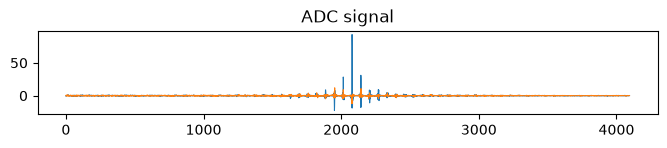

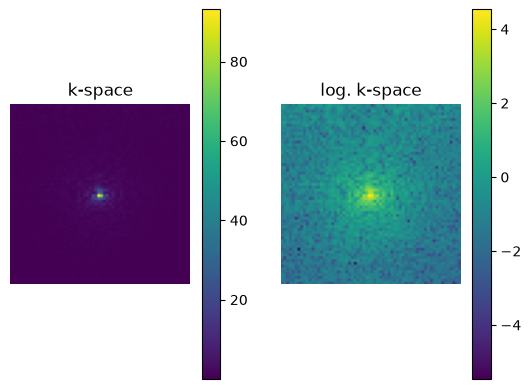

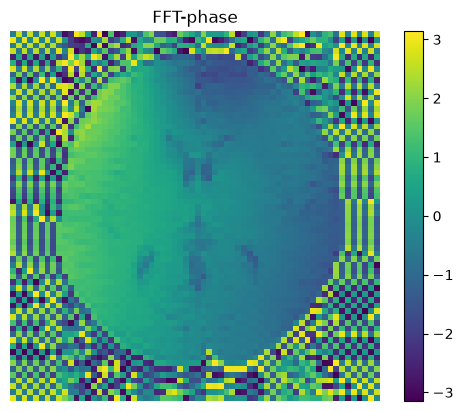

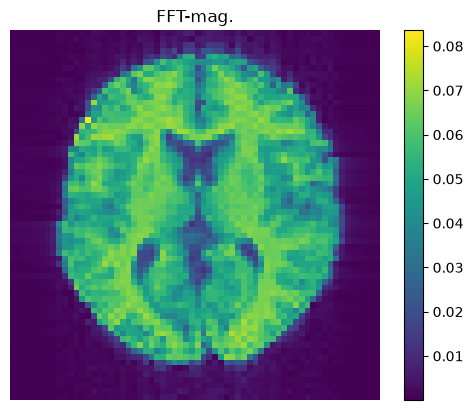

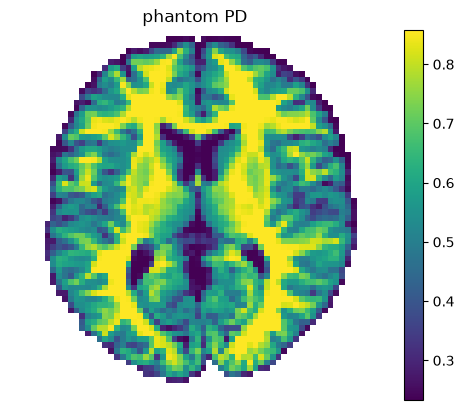

In [42]:
#@title 2D GRE in a brain phantom - reconstruction
# 2D FFT
def ifft_2d(x):
    return np.fft.fftshift(np.fft.ifftn(np.fft.ifftshift(x)))

kspace = np.reshape(signal, (Nphase, Nread))
im = ifft_2d(kspace)

fig = plt.figure(figsize=(8, 5))  # fig.clf()
plt.subplot(411)
plt.title('ADC signal')
plt.plot(np.real(signal), label='real')
plt.plot(np.imag(signal), label='imag')

plt.figure()
plt.subplot(121)
plt.title('k-space')
plt.imshow(np.abs(kspace)); plt.axis('off');plt.colorbar()
plt.subplot(122)
plt.title('log. k-space')
plt.imshow(np.log(np.abs(kspace))); plt.axis('off');plt.colorbar()
plt.figure()
plt.title('FFT-phase')
plt.imshow(np.angle(im), vmin=-np.pi, vmax=np.pi, origin="lower"); plt.axis('off')
plt.colorbar()
plt.figure()
plt.title('FFT-mag.')
plt.imshow(np.abs(im), origin="lower"); plt.axis('off');plt.colorbar()
plt.figure()
plt.title('phantom PD') # hint: use PD/T1 as a surrogate for the expected signal intensity
plt.imshow(PD.squeeze().T / T1.squeeze().T, origin="lower"); plt.axis('off');plt.colorbar()